In [1]:
import pandas, numpy, scipy, re

In [2]:
import sklearn, sklearn.preprocessing, sklearn.decomposition

In [44]:
import matplotlib, matplotlib.pyplot
matplotlib.rcParams.update({'font.size':20, 
                            'font.family':'sans-serif', 
                            'xtick.labelsize':16, 
                            'ytick.labelsize':16, 
                            'figure.figsize':(16*(2/3), 9*(2/3)), 
                            'axes.labelsize':20
                           })

# 0. user-defined variables

In [4]:
input_file = '/Users/adrian/research/bmcbf/094/results/profiles/DESeq2_TPM_values.newnames.tsv'

# 1. read expression

In [5]:
expression = pandas.read_csv(input_file, sep='\t', index_col=0)
print(expression.shape)
expression

(39546, 24)


,AEG13_AZM_1,AEG13_AZM_2,AEG13_AZM_3,AEG13_AZM_CPAD_1,AEG13_AZM_CPAD_2,AEG13_AZM_CPAD_3,AEG13_DMSO_1,AEG13_DMSO_2,AEG13_DMSO_3,AEG14_DMSO_1,...,AEG13_DMSO_CPAD_3,AEG14_DMSO_CPAD_1,AEG14_DMSO_CPAD_2,AEG14_DMSO_CPAD_3,AEG14_EP317_1,AEG14_EP317_2,AEG14_EP317_3,AEG14_EP317_CPAD_1,AEG14_EP317_CPAD_2,AEG14_EP317_CPAD_3
ENSG00000000003.15,5.271154,6.178072,6.744494,2.071064,0.902343,11.604521,7.882524,7.743843,7.095529,6.299442,...,1.717708,3.521996,2.301864,18.394391,6.626069,7.687138,5.492332,3.847536,1.555056,8.933537
ENSG00000000005.6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000000419.14,105.653503,103.888254,116.121718,30.113603,15.549739,60.362161,107.096641,102.007326,111.691002,103.201875,...,13.892038,42.417737,22.802559,63.261098,118.228811,127.676243,117.057138,53.527505,23.377234,50.480508
ENSG00000000457.14,8.049658,9.127055,8.963118,1.715814,0.604046,8.629745,9.554977,9.224226,8.612612,8.696535,...,0.907829,1.613968,0.749145,11.681868,8.362960,8.791572,9.028933,2.242259,0.648430,8.388056
ENSG00000000460.17,11.129310,11.095287,13.031090,2.523449,0.756014,5.145967,12.761046,12.661063,12.185397,12.159108,...,1.513987,3.258428,1.658790,5.278384,12.791956,13.407216,13.418040,3.301492,1.253288,3.245959
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENSG00000291297.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.081414,0.000000,0.000000,...,0.000000,0.000000,0.141474,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000291298.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000291299.1,1.809052,1.735516,1.800866,0.776747,0.110439,0.719545,1.046590,1.688838,1.755624,1.123504,...,0.345635,0.141398,0.607101,0.715834,1.511419,1.794607,2.955855,0.289749,0.121976,0.882873
ENSG00000291300.1,0.000000,0.000000,0.000000,0.325883,0.252090,0.083753,0.000000,0.000000,0.000000,0.000000,...,0.580021,0.046010,0.258690,0.045553,0.000000,0.000000,0.000000,0.000000,0.095306,0.091969


In [6]:
for element in expression.columns:
    print(element)

AEG13_AZM_1
AEG13_AZM_2
AEG13_AZM_3
AEG13_AZM_CPAD_1
AEG13_AZM_CPAD_2
AEG13_AZM_CPAD_3
AEG13_DMSO_1
AEG13_DMSO_2
AEG13_DMSO_3
AEG14_DMSO_1
AEG14_DMSO_2
AEG14_DMSO_3
AEG13_DMSO_CPAD_1
AEG13_DMSO_CPAD_2
AEG13_DMSO_CPAD_3
AEG14_DMSO_CPAD_1
AEG14_DMSO_CPAD_2
AEG14_DMSO_CPAD_3
AEG14_EP317_1
AEG14_EP317_2
AEG14_EP317_3
AEG14_EP317_CPAD_1
AEG14_EP317_CPAD_2
AEG14_EP317_CPAD_3


# 3. filter and transform

In [7]:
groups = pandas.Series([re.sub(r'\d+$', '', c) for c in expression.columns],
                       index=expression.columns, name='group')

print(groups.index.to_series().groupby(groups.values).agg(list))   # check grouping

group_medians = expression.T.groupby(groups).median().T            # genes × conditions

substantial_expression = expression[group_medians.max(axis=1) >= 2]
high_expression        = expression[group_medians.max(axis=1) >= 100]
print(substantial_expression.shape, high_expression.shape)

AEG13_AZM_                     [AEG13_AZM_1, AEG13_AZM_2, AEG13_AZM_3]
AEG13_AZM_CPAD_      [AEG13_AZM_CPAD_1, AEG13_AZM_CPAD_2, AEG13_AZM...
AEG13_DMSO_                 [AEG13_DMSO_1, AEG13_DMSO_2, AEG13_DMSO_3]
AEG13_DMSO_CPAD_     [AEG13_DMSO_CPAD_1, AEG13_DMSO_CPAD_2, AEG13_D...
AEG14_DMSO_                 [AEG14_DMSO_1, AEG14_DMSO_2, AEG14_DMSO_3]
AEG14_DMSO_CPAD_     [AEG14_DMSO_CPAD_1, AEG14_DMSO_CPAD_2, AEG14_D...
AEG14_EP317_             [AEG14_EP317_1, AEG14_EP317_2, AEG14_EP317_3]
AEG14_EP317_CPAD_    [AEG14_EP317_CPAD_1, AEG14_EP317_CPAD_2, AEG14...
dtype: object
(12453, 24) (1182, 24)


In [8]:
group_medians

group,AEG13_AZM_,AEG13_AZM_CPAD_,AEG13_DMSO_,AEG13_DMSO_CPAD_,AEG14_DMSO_,AEG14_DMSO_CPAD_,AEG14_EP317_,AEG14_EP317_CPAD_
ENSG00000000003.15,6.178072,2.071064,7.743843,2.382964,7.069473,3.521996,6.626069,3.847536
ENSG00000000005.6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000000419.14,105.653503,30.113603,107.096641,22.959803,112.728705,42.417737,118.228811,50.480508
ENSG00000000457.14,8.963118,1.715814,9.224226,1.343611,9.178815,1.613968,8.791572,2.242259
ENSG00000000460.17,11.129310,2.523449,12.661063,3.029451,13.796534,3.258428,13.407216,3.245959
...,...,...,...,...,...,...,...,...
ENSG00000291297.1,0.000000,0.000000,0.000000,0.000000,0.077277,0.000000,0.000000,0.000000
ENSG00000291298.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000291299.1,1.800866,0.719545,1.688838,0.407246,1.891630,0.607101,1.794607,0.289749
ENSG00000291300.1,0.000000,0.252090,0.000000,0.262434,0.000000,0.046010,0.000000,0.091969


In [9]:
transpose = substantial_expression.transpose()
pca_substantial_expression = numpy.log2(transpose + 1)

transpose = high_expression.transpose()
pca_high_expression = numpy.log2(transpose + 1)

# 4. visualize substantial expression

In [10]:
scaled_data = sklearn.preprocessing.StandardScaler().fit_transform(pca_substantial_expression)
model = sklearn.decomposition.PCA(n_components=2)
new = model.fit_transform(scaled_data)
explained = model.explained_variance_ratio_
print(explained)

[0.64678764 0.17456089]


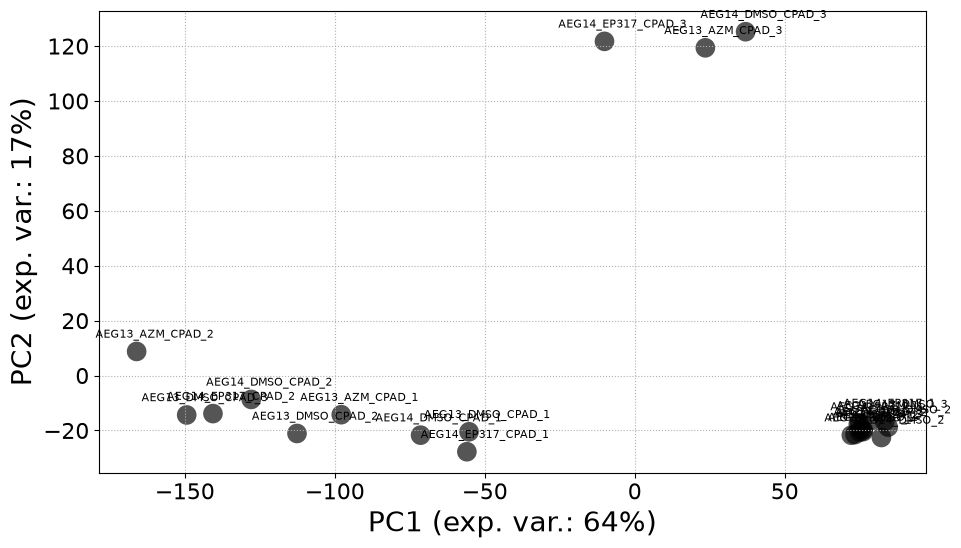

In [11]:
for i in range(len(new)):

    name = pca_substantial_expression.index[i]
        
    matplotlib.pyplot.scatter(new[i,0], new[i,1], s=200, c='black', marker='o', alpha=2/3, edgecolors='none')
    epsilon=6
    matplotlib.pyplot.text(new[i,0]+epsilon, new[i,1]+epsilon, name, size=8, va='center', ha='center')
    
matplotlib.pyplot.xlabel('PC1 (exp. var.: {}%)'.format(int(explained[0]*100)))
matplotlib.pyplot.ylabel('PC2 (exp. var.: {}%)'.format(int(explained[1]*100)))
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.show()

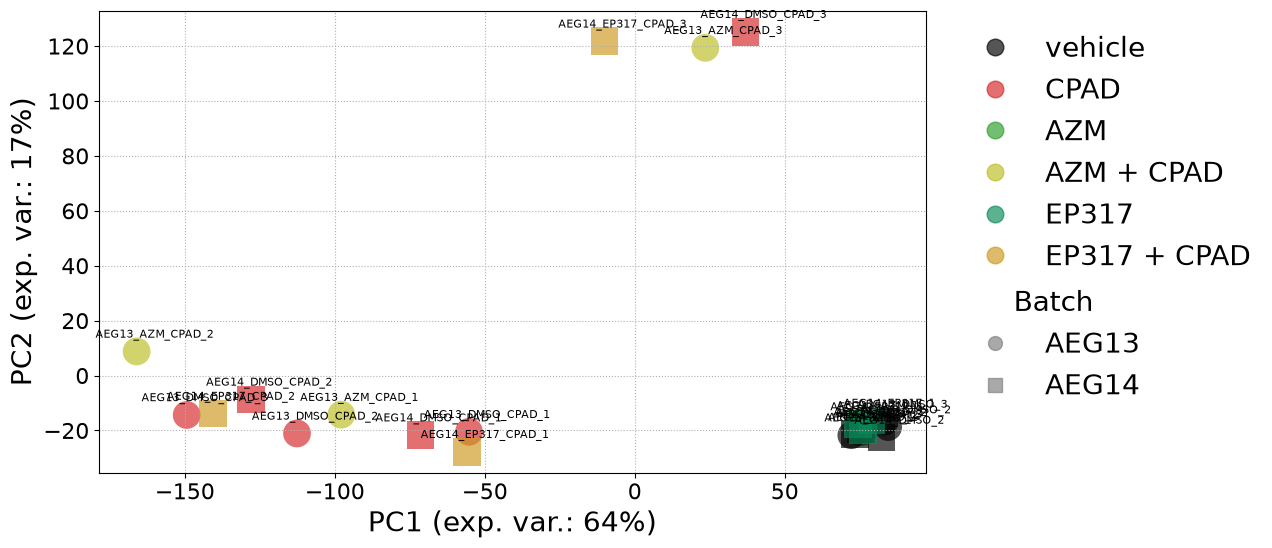

In [22]:
PALETTE = {
    ('DMSO',  False): '#000000',
    ('DMSO',  True):  '#d62728',
    ('AZM',   False): '#2ca02c',
    ('AZM',   True):  '#bcbd22',
    ('EP317', False): '#0b8a5a',
    ('EP317', True):  '#cc9a1f',
}
LABELS = {
    ('DMSO',  False): 'vehicle',
    ('DMSO',  True):  'CPAD',
    ('AZM',   False): 'AZM',
    ('AZM',   True):  'AZM + CPAD',
    ('EP317', False): 'EP317',
    ('EP317', True):  'EP317 + CPAD',
}
MARKERS = {'AEG13': 'o', 'AEG14': 's'}


for i in range(len(new)):

    name = pca_substantial_expression.index[i]
    parts = name.split('_')
    batch, drug, cpad = parts[0], parts[1], 'CPAD' in parts

    the_color = PALETTE[(drug, cpad)]
    the_marker = MARKERS[batch]

    matplotlib.pyplot.scatter(new[i, 0], new[i, 1], s=400, color=the_color, marker=the_marker, alpha=2/3, edgecolors='none')
    epsilon=6
    matplotlib.pyplot.text(new[i,0]+epsilon, new[i,1]+epsilon, name, size=8, va='center', ha='center')

color_elements = [
    matplotlib.lines.Line2D([], [], marker='o', linestyle='none', markersize=12,
                            color=PALETTE[k], alpha=2/3, label=LABELS[k])
    for k in PALETTE
]
marker_elements = [
    matplotlib.lines.Line2D([], [], marker=m, linestyle='none', markersize=10,
                            color='#7f7f7f', alpha=2/3, label=b)
    for b, m in MARKERS.items()
]

first = matplotlib.pyplot.legend(color_elements, [e.get_label() for e in color_elements],
                                 loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
matplotlib.pyplot.gca().add_artist(first)
matplotlib.pyplot.legend(marker_elements, [e.get_label() for e in marker_elements],
                         loc='upper left', bbox_to_anchor=(1.02, 0.45), frameon=False,
                         title='Batch')

matplotlib.pyplot.xlabel('PC1 (exp. var.: {}%)'.format(int(explained[0]*100)))
matplotlib.pyplot.ylabel('PC2 (exp. var.: {}%)'.format(int(explained[1]*100)))
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.show()

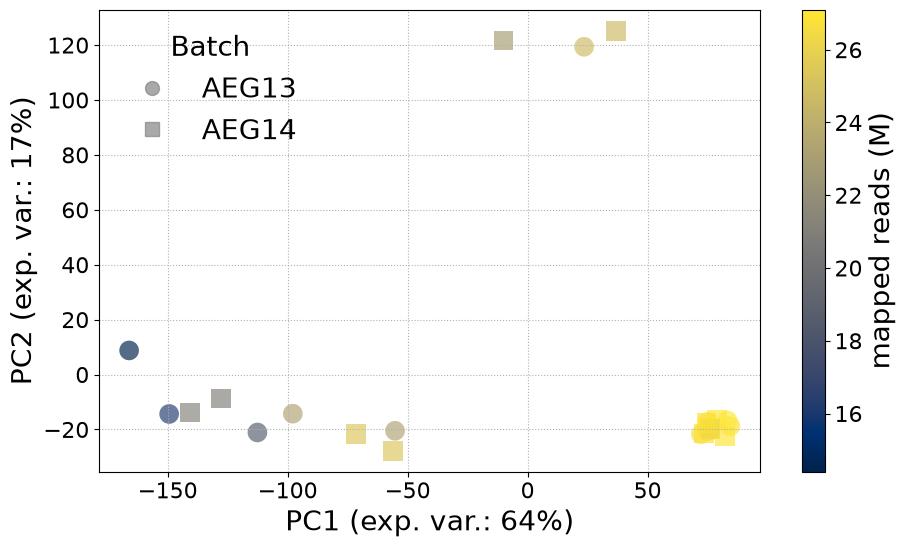

In [47]:
import matplotlib.pyplot
import matplotlib.lines
import matplotlib.colors
import matplotlib.cm

MARKERS = {'AEG13': 'o', 'AEG14': 's'}

MAPPED = {
    'AEG13_AZM_1': 26.9,        'AEG13_AZM_2': 26.8,        'AEG13_AZM_3': 26.8,
    'AEG13_AZM_CPAD_1': 23.3,   'AEG13_AZM_CPAD_2': 14.4,   'AEG13_AZM_CPAD_3': 24.7,
    'AEG13_DMSO_1': 26.6,       'AEG13_DMSO_2': 26.9,       'AEG13_DMSO_3': 27.1,
    'AEG13_DMSO_CPAD_1': 23.3,  'AEG13_DMSO_CPAD_2': 18.7,  'AEG13_DMSO_CPAD_3': 16.2,
    'AEG14_DMSO_1': 26.8,       'AEG14_DMSO_2': 27.0,       'AEG14_DMSO_3': 26.8,
    'AEG14_DMSO_CPAD_1': 25.4,  'AEG14_DMSO_CPAD_2': 21.0,  'AEG14_DMSO_CPAD_3': 24.7,
    'AEG14_EP317_1': 27.0,      'AEG14_EP317_2': 26.3,      'AEG14_EP317_3': 26.8,
    'AEG14_EP317_CPAD_1': 25.4, 'AEG14_EP317_CPAD_2': 21.2, 'AEG14_EP317_CPAD_3': 22.9,
}

cmap = matplotlib.pyplot.get_cmap('cividis')
norm = matplotlib.colors.Normalize(vmin=min(MAPPED.values()), vmax=max(MAPPED.values()))

matplotlib.pyplot.figure(figsize=(16*(2/3), 9*(2/3)))

for i in range(len(new)):

    name = pca_substantial_expression.index[i]
    parts = name.split('_')
    batch, drug, cpad = parts[0], parts[1], 'CPAD' in parts

    the_color = cmap(norm(MAPPED[name]))
    the_marker = MARKERS[batch]

    matplotlib.pyplot.scatter(new[i, 0], new[i, 1], s=200, color=the_color, marker=the_marker, alpha=2/3, edgecolors='none')

marker_elements = [
    matplotlib.lines.Line2D([], [], marker=m, linestyle='none', markersize=10,
                            color='#7f7f7f', alpha=2/3, label=b)
    for b, m in MARKERS.items()
]

matplotlib.pyplot.legend(marker_elements, [e.get_label() for e in marker_elements],
                         loc='upper left', frameon=False, title='Batch')

mappable = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
matplotlib.pyplot.colorbar(mappable, ax=matplotlib.pyplot.gca(), label='mapped reads (M)')

matplotlib.pyplot.xlabel('PC1 (exp. var.: {}%)'.format(int(explained[0]*100)))
matplotlib.pyplot.ylabel('PC2 (exp. var.: {}%)'.format(int(explained[1]*100)))
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.show()

# 4. visualize high expression

# 5. distributions

In [23]:
log2_tpm_PO = numpy.log2(expression + 1)
log2_tpm_PO.head()

,AEG13_AZM_1,AEG13_AZM_2,AEG13_AZM_3,AEG13_AZM_CPAD_1,AEG13_AZM_CPAD_2,AEG13_AZM_CPAD_3,AEG13_DMSO_1,AEG13_DMSO_2,AEG13_DMSO_3,AEG14_DMSO_1,...,AEG13_DMSO_CPAD_3,AEG14_DMSO_CPAD_1,AEG14_DMSO_CPAD_2,AEG14_DMSO_CPAD_3,AEG14_EP317_1,AEG14_EP317_2,AEG14_EP317_3,AEG14_EP317_CPAD_1,AEG14_EP317_CPAD_2,AEG14_EP317_CPAD_3
ENSG00000000003.15,2.648731,2.843596,2.953171,1.618739,0.927777,3.655869,3.150970,3.128268,3.017125,2.867786,...,1.442391,2.176960,1.723281,4.277568,2.930940,3.118881,2.698737,2.277252,1.353355,3.312307
ENSG00000000005.6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000000419.14,6.736788,6.712709,6.871865,4.959474,4.048737,5.939277,6.756178,6.686603,6.816229,6.703237,...,3.896469,5.440213,4.573045,6.005874,6.897589,7.007602,6.883341,5.768912,4.607463,5.685954
ENSG00000000457.14,3.177863,3.340143,3.316597,1.441385,0.681715,3.267498,3.399852,3.353920,3.264928,3.277469,...,0.931932,1.386241,0.806650,3.664695,3.226965,3.291541,3.326096,1.697000,0.721092,3.230826
ENSG00000000460.17,3.600426,3.596373,3.810555,1.816988,0.812305,2.619640,3.782518,3.771998,3.720869,3.717990,...,1.329977,2.090321,1.410770,2.650393,3.785755,3.848720,3.849803,2.104837,1.172032,2.086090


17.37185933856851


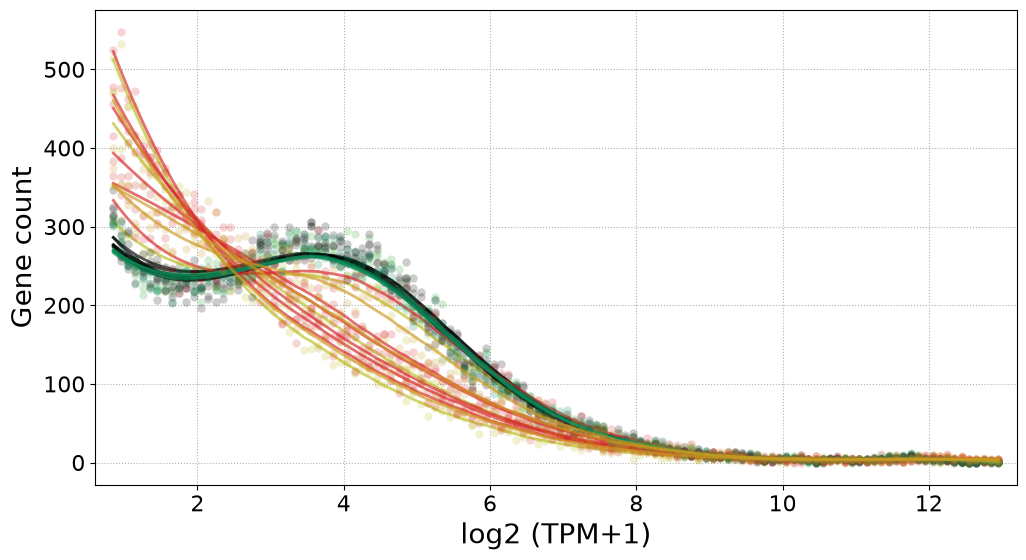

In [41]:
found_max = 17
number_of_bins = int(found_max*10)

absolute_max = 0
working_samples = log2_tpm_PO.columns.to_list()

most_likely_expressions = []
all_hats = []
for i in range(len(working_samples)):

    name = working_samples[i]

    # colors
    if 'AZM_CPAD' in name:
        the_color = 'tab:olive'
    elif 'EP317_CPAD' in name:
        the_color = '#cc9a1f'
    elif 'DMSO_CPAD' in name:
        the_color = 'tab:red'
    elif 'AZM' in name:
        the_color = 'tab:green'
    elif 'EP317' in name:
        the_color = '#0b8a5a'
    elif 'DMSO' in name:
        the_color = 'black'
    else:
        print('error')

    
    log2TPM = log2_tpm_PO.loc[:, name]
    if max(log2TPM) > absolute_max:
        absolute_max = max(log2TPM)
                
    hist, bin_edges = numpy.histogram(log2TPM, bins=number_of_bins, range=(0, found_max))
    half_bin = (bin_edges[1] - bin_edges[0])/2
    x = bin_edges + half_bin
    x = x[:-1]
  
    plotting_x = x[8:-40]
    plotting_hist = hist[8:-40]
    #print(plotting_x)
    
    matplotlib.pyplot.plot(plotting_x, plotting_hist, 'o', alpha=1/5, mec='none', color=the_color)
    yhat = scipy.signal.savgol_filter(plotting_hist, 51, 3)

    matplotlib.pyplot.plot(plotting_x, yhat, '-', lw=2, alpha=2/3, color=the_color)
    
matplotlib.pyplot.xlim([numpy.min(plotting_x)-0.25, numpy.max(plotting_x)+0.25])

#matplotlib.pyplot.legend(legend_elements, ['Day 0', 'Day 7', 'Day 15', 'Day 21', 'Day 28', 'Day 35'], ncol=1, loc='upper left', bbox_to_anchor=(1.05, 1))

#legend_elements = [
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='black',      edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:blue',    edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='gold',    edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:orange',    edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:red',    edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:purple',    edgecolor='white', alpha=2/3),
#]    

matplotlib.pyplot.xlabel('log2 (TPM+1)')
matplotlib.pyplot.ylabel('Gene count')
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.tight_layout()

print(absolute_max)
